# FIFA World Cup 2026 Match Prediction using Machine Learning

## Project Overview

The FIFA World Cup is one of the most prestigious sporting events in the world. Predicting football match outcomes is a challenging task due to the uncertainty and dynamic nature of the sport. This project aims to develop a Machine Learning model capable of predicting the outcomes of international football matches using historical match data.

The model will be trained on historical international football results and will learn patterns based on team performances. After training, the model will be used to predict FIFA World Cup 2026 fixtures and simulate the tournament.

## Objectives

- Load and analyze historical football match data.
- Perform data preprocessing and feature engineering.
- Calculate Elo ratings for national teams.
- Train a Machine Learning classification model.
- Evaluate model performance.
- Predict FIFA World Cup 2026 match outcomes.
- Simulate the entire tournament.

In [121]:
# Importing required libraries

import pandas as pd
import numpy as np


# Visualization libraries

import matplotlib.pyplot as plt
import seaborn as sns


# Machine Learning libraries

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# ML Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


# Ignore warnings

import warnings
warnings.filterwarnings('ignore')

In [122]:
# Load the dataset

df = pd.read_csv("results.csv")

In [123]:
# Display first 5 rows

df.head()

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0.0,0.0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4.0,2.0,Friendly,London,England,False
2,1874-03-07,Scotland,England,2.0,1.0,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2.0,2.0,Friendly,London,England,False
4,1876-03-04,Scotland,England,3.0,0.0,Friendly,Glasgow,Scotland,False


In [124]:
# Number of rows and columns

df.shape

(49505, 9)

In [125]:
# Checking column names

df.columns

Index(['date', 'home_team', 'away_team', 'home_score', 'away_score',
       'tournament', 'city', 'country', 'neutral'],
      dtype='object')

In [126]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49505 entries, 0 to 49504
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        49505 non-null  object 
 1   home_team   49505 non-null  object 
 2   away_team   49505 non-null  object 
 3   home_score  49501 non-null  float64
 4   away_score  49501 non-null  float64
 5   tournament  49505 non-null  object 
 6   city        49505 non-null  object 
 7   country     49505 non-null  object 
 8   neutral     49505 non-null  bool   
dtypes: bool(1), float64(2), object(6)
memory usage: 3.1+ MB


In [127]:
# Checking missing values in each column

df.isnull().sum()

date          0
home_team     0
away_team     0
home_score    4
away_score    4
tournament    0
city          0
country       0
neutral       0
dtype: int64

In [128]:
# Removing missing values

df = df.dropna()
df.isnull().sum()

date          0
home_team     0
away_team     0
home_score    0
away_score    0
tournament    0
city          0
country       0
neutral       0
dtype: int64

In [129]:
# Checking duplicate rows

df.duplicated().sum()

0

In [130]:
# Convert date column into datetime format

df['date'] = pd.to_datetime(df['date'])


# Check datatype

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49501 entries, 0 to 49500
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        49501 non-null  datetime64[ns]
 1   home_team   49501 non-null  object        
 2   away_team   49501 non-null  object        
 3   home_score  49501 non-null  float64       
 4   away_score  49501 non-null  float64       
 5   tournament  49501 non-null  object        
 6   city        49501 non-null  object        
 7   country     49501 non-null  object        
 8   neutral     49501 non-null  bool          
dtypes: bool(1), datetime64[ns](1), float64(2), object(5)
memory usage: 3.4+ MB


In [131]:
# Checking data types of score columns

df[['home_score', 'away_score']].dtypes

home_score    float64
away_score    float64
dtype: object

In [132]:
# Convert goal columns from float to integer

df['home_score'] = df['home_score'].astype(int)
df['away_score'] = df['away_score'].astype(int)


# Verify conversion

df[['home_score', 'away_score']].dtypes

home_score    int32
away_score    int32
dtype: object

In [133]:
df.dtypes

date          datetime64[ns]
home_team             object
away_team             object
home_score             int32
away_score             int32
tournament            object
city                  object
country               object
neutral                 bool
dtype: object

In [134]:
# Creating target variable

def get_result(row):
    
    # Home team wins
    
    if row['home_score'] > row['away_score']:
        return 2
    
    # Match draw
    
    elif row['home_score'] == row['away_score']:
        return 1
    
    # Away team wins
    
    else:
        return 0



# Applying function to every match

df['result'] = df.apply(get_result, axis=1)


# Checking results

df.head()

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,result
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False,1
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False,2
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False,2
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False,1
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False,2


In [135]:
# Counting match outcomes

df['result'].value_counts()

result
2    24257
0    13987
1    11257
Name: count, dtype: int64

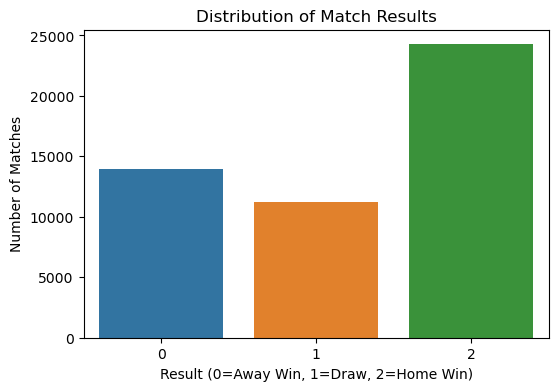

In [136]:
#Visualize result distribution

plt.figure(figsize=(6,4))

sns.countplot(
    x='result',
    data=df
)

plt.title("Distribution of Match Results")

plt.xlabel(
    "Result (0=Away Win, 1=Draw, 2=Home Win)"
)

plt.ylabel("Number of Matches")

plt.show()

In [137]:
# Removing unnecessary columns

df = df.drop(
    [
        'city',
        'country'
    ],
    axis=1
)


# Check remaining columns

df.head()

,date,home_team,away_team,home_score,away_score,tournament,neutral,result
0,1872-11-30,Scotland,England,0,0,Friendly,False,1
1,1873-03-08,England,Scotland,4,2,Friendly,False,2
2,1874-03-07,Scotland,England,2,1,Friendly,False,2
3,1875-03-06,England,Scotland,2,2,Friendly,False,1
4,1876-03-04,Scotland,England,3,0,Friendly,False,2


In [138]:
# Creating encoder

encoder = LabelEncoder()


# Encoding home teams

df['home_team_encoded'] = encoder.fit_transform(
    df['home_team']
)


# Encoding away teams

df['away_team_encoded'] = encoder.fit_transform(
    df['away_team']
)


df.head()

,date,home_team,away_team,home_score,away_score,tournament,neutral,result,home_team_encoded,away_team_encoded
0,1872-11-30,Scotland,England,0,0,Friendly,False,1,250,88
1,1873-03-08,England,Scotland,4,2,Friendly,False,2,86,245
2,1874-03-07,Scotland,England,2,1,Friendly,False,2,250,88
3,1875-03-06,England,Scotland,2,2,Friendly,False,1,86,245
4,1876-03-04,Scotland,England,3,0,Friendly,False,2,250,88


In [139]:
# Selecting input features

X = df[
    [
        'home_team_encoded',
        'away_team_encoded',
        'neutral'
    ]
]


# Target variable

y = df['result']


print(X.head())
print(y.head())

   home_team_encoded  away_team_encoded  neutral
0                250                 88    False
1                 86                245    False
2                250                 88    False
3                 86                245    False
4                250                 88    False
0    1
1    2
2    2
3    1
4    2
Name: result, dtype: int64


In [140]:
# Splitting dataset

X_train, X_test, y_train, y_test = train_test_split(
    
    X,
    y,
    test_size=0.2,
    random_state=42

)


print(
    X_train.shape,
    X_test.shape
)

(39600, 3) (9901, 3)


In [141]:
# Creating model

model = LogisticRegression(
    max_iter=1000
)


# Training model

model.fit(
    X_train,
    y_train
)

LogisticRegression(max_iter=1000)

In [142]:
# Making predictions

predictions = model.predict(
    X_test
)


# Accuracy

accuracy = accuracy_score(
    y_test,
    predictions
)


print(
    "Accuracy:",
    accuracy
)

Accuracy: 0.49641450358549644


# Feature Engineering
## Feature 1: Team Win Percentage
A team's historical strength can be represented as:

Win Percentage = Total Matches/Wins

In [143]:
# Creating dictionary

team_stats = {}


for index, row in df.iterrows():

    home = row['home_team']
    away = row['away_team']


    # Initialize teams
    
    for team in [home, away]:
        
        if team not in team_stats:
            
            team_stats[team] = {
                'matches':0,
                'wins':0
            }


    # Count matches
    
    team_stats[home]['matches'] += 1
    team_stats[away]['matches'] += 1


    # Count wins
    
    if row['result'] == 2:
        
        # Home team won
        
        team_stats[home]['wins'] += 1


    elif row['result'] == 0:
        
        # Away team won
        
        team_stats[away]['wins'] += 1

#Example

team_stats['Brazil']

{'matches': 1064, 'wins': 675}

In [144]:
# Creating win percentage dictionary

win_percentage = {}


for team, stats in team_stats.items():

    win_percentage[team] = (
        stats['wins'] / stats['matches']
    )

#Example

win_percentage['Brazil']

0.6343984962406015

In [145]:
# Add home team win percentage

df['home_win_percentage'] = (
    df['home_team']
    .map(win_percentage)
)


# Add away team win percentage

df['away_win_percentage'] = (
    df['away_team']
    .map(win_percentage)
)

In [146]:
# Selecting input features

X = df[
    [
        'home_win_percentage',
        'away_win_percentage' 
    ]
]


# Target variable

y = df['result']


print(X.head())
print(y.head())

   home_win_percentage  away_win_percentage
0             0.471897             0.574429
1             0.574429             0.471897
2             0.471897             0.574429
3             0.574429             0.471897
4             0.471897             0.574429
0    1
1    2
2    2
3    1
4    2
Name: result, dtype: int64


In [147]:
# Splitting dataset

X_train, X_test, y_train, y_test = train_test_split(
    
    X,
    y,
    test_size=0.2,
    random_state=42

)


print(
    X_train.shape,
    X_test.shape
)

(39600, 2) (9901, 2)


In [148]:
# Creating model

model = LogisticRegression(
    max_iter=1000
)


# Training model

model.fit(
    X_train,
    y_train
)

LogisticRegression(max_iter=1000)

In [149]:
# Making predictions

predictions = model.predict(
    X_test
)


# Accuracy

accuracy = accuracy_score(
    y_test,
    predictions
)


print(
    "Accuracy:",
    accuracy
)

Accuracy: 0.5661044338955661


## Feature 2: Last 5 Matches Form

In [150]:
# Sort matches from oldest to newest

df = df.sort_values('date').reset_index(drop=True)

In [151]:
# Create new columns for form scores

df['home_form'] = 0.0
df['away_form'] = 0.0

In [152]:
# Dictionary to store each team's recent match points

team_form = {}

In [153]:
# Calculate recent form for every match

for index, row in df.iterrows():

    home = row['home_team']
    away = row['away_team']

    # Initialize new teams
    
    if home not in team_form:
        team_form[home] = []

    if away not in team_form:
        team_form[away] = []

    # Calculate form BEFORE this match
    
    if len(team_form[home]) > 0:
        df.at[index, 'home_form'] = sum(team_form[home][-5:]) / 15

    if len(team_form[away]) > 0:
        df.at[index, 'away_form'] = sum(team_form[away][-5:]) / 15

    # Update histories AFTER this match
    
    if row['result'] == 2:

        team_form[home].append(3)
        team_form[away].append(0)

    elif row['result'] == 1:

        team_form[home].append(1)
        team_form[away].append(1)

    else:

        team_form[home].append(0)
        team_form[away].append(3)

In [154]:
df[['home_team', 'away_team', 'home_form', 'away_form']].head(10)

,home_team,away_team,home_form,away_form
0,Scotland,England,0.000000,0.000000
1,England,Scotland,0.066667,0.066667
2,Scotland,England,0.066667,0.266667
3,England,Scotland,0.266667,0.266667
4,Scotland,England,0.333333,0.333333
5,Scotland,Wales,0.533333,0.000000
6,England,Scotland,0.333333,0.666667
7,Wales,Scotland,0.000000,0.866667
8,Scotland,England,0.866667,0.266667
9,Scotland,Wales,1.000000,0.000000


In [155]:
# Selecting input features

X = df[
    [
        'home_team_encoded',
        'away_team_encoded',
        'neutral',
        'home_win_percentage',
        'away_win_percentage',
        'home_form',
        'away_form'
    ]
]

# Target variable
y = df['result']

In [156]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [157]:
# Create the model

model = LogisticRegression(max_iter=1000)

# Train the model

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [158]:
# Predict the match results

predictions = model.predict(X_test)

In [159]:
# Accuracy

accuracy = accuracy_score(y_test, predictions)
print("Accuracy:", accuracy)

Accuracy: 0.5721644278355722


## Feature 3: Average Goals Scored

In [160]:
# Create columns

df['home_avg_goals'] = 0.0
df['away_avg_goals'] = 0.0

# Dictionary to store goals scored

team_goals = {}

# Process matches in chronological order

for index, row in df.iterrows():

    home = row['home_team']
    away = row['away_team']

    # Initialize new teams
    
    if home not in team_goals:
        team_goals[home] = []

    if away not in team_goals:
        team_goals[away] = []

    # Calculate average goals BEFORE current match
    
    if len(team_goals[home]) > 0:
        df.at[index, 'home_avg_goals'] = (
            sum(team_goals[home]) / len(team_goals[home])
        )

    if len(team_goals[away]) > 0:
        df.at[index, 'away_avg_goals'] = (
            sum(team_goals[away]) / len(team_goals[away])
        )

    # Update goal history AFTER current match
    
    team_goals[home].append(row['home_score'])
    team_goals[away].append(row['away_score'])

In [161]:
df[['home_team',
    'away_team',
    'home_avg_goals',
    'away_avg_goals']].head(10)

,home_team,away_team,home_avg_goals,away_avg_goals
0,Scotland,England,0.000000,0.000000
1,England,Scotland,0.000000,0.000000
2,Scotland,England,1.000000,2.000000
3,England,Scotland,1.666667,1.333333
4,Scotland,England,1.500000,1.750000
5,Scotland,Wales,1.800000,0.000000
6,England,Scotland,1.400000,2.166667
7,Wales,Scotland,0.000000,2.285714
8,Scotland,England,2.250000,1.333333
9,Scotland,Wales,2.777778,0.000000


## Feature 4: Average Goals Conceded

In [162]:
# Create columns

df['home_avg_conceded'] = 0.0
df['away_avg_conceded'] = 0.0


# Dictionary

team_conceded = {}


# Process matches chronologically

for index, row in df.iterrows():

    home = row['home_team']
    away = row['away_team']


    # Initialize teams
    
    if home not in team_conceded:
        team_conceded[home] = []

    if away not in team_conceded:
        team_conceded[away] = []


    # Calculate defensive average BEFORE match
    
    if len(team_conceded[home]) > 0:

        df.at[index, 'home_avg_conceded'] = (
            sum(team_conceded[home]) /
            len(team_conceded[home])
        )


    if len(team_conceded[away]) > 0:

        df.at[index, 'away_avg_conceded'] = (
            sum(team_conceded[away]) /
            len(team_conceded[away])
        )


    # Update AFTER match
    
    team_conceded[home].append(row['away_score'])
    team_conceded[away].append(row['home_score'])

In [163]:
df[
[
'home_team',
'away_team',
'home_avg_conceded',
'away_avg_conceded'
]
].head(20)

,home_team,away_team,home_avg_conceded,away_avg_conceded
0,Scotland,England,0.000000,0.000000
1,England,Scotland,0.000000,0.000000
2,Scotland,England,2.000000,1.000000
3,England,Scotland,1.333333,1.666667
4,Scotland,England,1.750000,1.500000
5,Scotland,Wales,1.400000,0.000000
6,England,Scotland,1.800000,1.166667
7,Wales,Scotland,4.000000,1.142857
8,Scotland,England,1.000000,2.000000
9,Scotland,Wales,1.111111,3.000000


In [164]:
# Check feature values

df[
[
'home_team',
'away_team',
'home_form',
'away_form',
'home_avg_goals',
'away_avg_goals',
'home_avg_conceded',
'away_avg_conceded'
]
].head(20)

,home_team,away_team,home_form,away_form,home_avg_goals,away_avg_goals,home_avg_conceded,away_avg_conceded
0,Scotland,England,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,England,Scotland,0.066667,0.066667,0.000000,0.000000,0.000000,0.000000
2,Scotland,England,0.066667,0.266667,1.000000,2.000000,2.000000,1.000000
3,England,Scotland,0.266667,0.266667,1.666667,1.333333,1.333333,1.666667
4,Scotland,England,0.333333,0.333333,1.500000,1.750000,1.750000,1.500000
5,Scotland,Wales,0.533333,0.000000,1.800000,0.000000,1.400000,0.000000
6,England,Scotland,0.333333,0.666667,1.400000,2.166667,1.800000,1.166667
7,Wales,Scotland,0.000000,0.866667,0.000000,2.285714,4.000000,1.142857
8,Scotland,England,0.866667,0.266667,2.250000,1.333333,1.000000,2.000000
9,Scotland,Wales,1.000000,0.000000,2.777778,0.000000,1.111111,3.000000


## Feature 5: Goal Difference 

Goal Difference = Average Goals Scored - Average Goals Conceded

In [165]:
# Creating goal difference features

df['home_goal_difference'] = (
    df['home_avg_goals'] -
    df['home_avg_conceded']
)


df['away_goal_difference'] = (
    df['away_avg_goals'] -
    df['away_avg_conceded']
)

In [166]:
# Check the feature

df[
[
'home_team',
'away_team',
'home_avg_goals',
'home_avg_conceded',
'home_goal_difference'
]
].head(20)

,home_team,away_team,home_avg_goals,home_avg_conceded,home_goal_difference
0,Scotland,England,0.000000,0.000000,0.000000
1,England,Scotland,0.000000,0.000000,0.000000
2,Scotland,England,1.000000,2.000000,-1.000000
3,England,Scotland,1.666667,1.333333,0.333333
4,Scotland,England,1.500000,1.750000,-0.250000
5,Scotland,Wales,1.800000,1.400000,0.400000
6,England,Scotland,1.400000,1.800000,-0.400000
7,Wales,Scotland,0.000000,4.000000,-4.000000
8,Scotland,England,2.250000,1.000000,1.250000
9,Scotland,Wales,2.777778,1.111111,1.666667


In [167]:
# Selecting input features

X = df[
[
'home_win_percentage',
'away_win_percentage',

'home_form',
'away_form',

'home_avg_goals',
'away_avg_goals',

'home_avg_conceded',
'away_avg_conceded',

'home_goal_difference',
'away_goal_difference'
]
]


y = df['result']

In [168]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [169]:
# Create the model

model = LogisticRegression(max_iter=1000)

# Train the model

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [170]:
# Predict the match results

predictions = model.predict(X_test)

In [171]:
# Accuracy

accuracy = accuracy_score(y_test, predictions)
print("Accuracy:", accuracy)

Accuracy: 0.5726694273305727


## Feature 6: Elo Rating System

In [172]:
df[
[
'home_goal_difference',
'away_goal_difference'
]
].describe()

,home_goal_difference,away_goal_difference
count,49501.000000,49501.000000
mean,-0.131095,-0.200397
std,1.115973,1.174746
min,-24.000000,-21.000000
25%,-0.550000,-0.619658
50%,0.026316,-0.008929
75%,0.531746,0.502825
max,16.000000,21.000000


In [173]:
# Create Elo columns

df['home_elo'] = 1500.0
df['away_elo'] = 1500.0
df['elo_difference'] = 0.0


# Dictionary

elo_ratings = {}

# Elo update factor

K = 32


# Process matches chronologically

for index, row in df.iterrows():

    home = row['home_team']
    away = row['away_team']

    # Initialize new teams

    if home not in elo_ratings:
        elo_ratings[home] = 1500

    if away not in elo_ratings:
        elo_ratings[away] = 1500

    # Current ratings BEFORE match

    home_elo = elo_ratings[home]
    away_elo = elo_ratings[away]

    # Store features

    df.at[index, 'home_elo'] = home_elo
    df.at[index, 'away_elo'] = away_elo
    df.at[index, 'elo_difference'] = home_elo - away_elo

    # Expected scores

    expected_home = 1 / (
        1 + 10 ** ((away_elo - home_elo) / 400)
    )

    expected_away = 1 - expected_home

    # Actual scores

    if row['result'] == 2:

        actual_home = 1
        actual_away = 0

    elif row['result'] == 1:

        actual_home = 0.5
        actual_away = 0.5

    else:

        actual_home = 0
        actual_away = 1

    # Update ratings

    elo_ratings[home] = (
        home_elo +
        K * (actual_home - expected_home)
    )

    elo_ratings[away] = (
        away_elo +
        K * (actual_away - expected_away)
    )

In [174]:
df[
[
'home_team',
'away_team',
'home_elo',
'away_elo',
'elo_difference'
]
].head(20)

,home_team,away_team,home_elo,away_elo,elo_difference
0,Scotland,England,1500.000000,1500.000000,0.000000
1,England,Scotland,1500.000000,1500.000000,0.000000
2,Scotland,England,1484.000000,1516.000000,-32.000000
3,England,Scotland,1498.530498,1501.469502,-2.939003
4,Scotland,England,1501.334159,1498.665841,2.668317
5,Scotland,Wales,1517.211281,1500.000000,17.211281
6,England,Scotland,1482.788719,1532.419319,-49.630600
7,Wales,Scotland,1484.791961,1546.149166,-61.357205
8,Scotland,England,1559.352575,1469.058873,90.293703
9,Scotland,Wales,1571.285550,1471.588552,99.696998


In [175]:
# Selecting final features

X = df[
[
    'home_team_encoded',
    'away_team_encoded',
    'neutral',

    'home_win_percentage',
    'away_win_percentage',

    'home_form',
    'away_form',

    'home_avg_goals',
    'away_avg_goals',

    'home_avg_conceded',
    'away_avg_conceded',

    'home_goal_difference',
    'away_goal_difference',

    'elo_difference'
]
]


# Target

y = df['result']

In [176]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    
    X,
    y,
    test_size=0.2,
    random_state=42

)

In [177]:
# Create the model

model = LogisticRegression(max_iter=1000)

# Train the model

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [178]:
y_pred = model.predict(X_test)

In [179]:
# Accuracy

accuracy = accuracy_score(
    y_test,
    y_pred
)


print(
    f"Accuracy: {accuracy:.2%}"
)

Accuracy: 58.48%


In [180]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.52      0.58      0.54      2724
           1       0.44      0.00      0.01      2231
           2       0.61      0.85      0.71      4946

    accuracy                           0.58      9901
   macro avg       0.52      0.48      0.42      9901
weighted avg       0.55      0.58      0.51      9901



## Feature 7: FIFA Ranking

In [181]:
# Load the FIFA rankings

fifa = pd.read_csv(
    "fifa_mens_rank.csv"
)


fifa.head()

,date,semester,rank,team,acronym,total.points,previous.points,diff.points
0,2024,2,1,Argentina,ARG,1867.25,1883.50,-16.25
1,2024,2,2,France,FRA,1859.78,1859.85,-0.07
2,2024,2,3,Spain,ESP,1853.27,1844.33,8.94
3,2024,2,4,England,ENG,1813.81,1807.83,5.98
4,2024,2,5,Brazil,BRA,1775.85,1784.37,-8.52


In [182]:
# Selecting the features

fifa = fifa[['team','rank']]

In [183]:
# Check the dataframe

fifa.shape

(13130, 2)

In [184]:
# Check the duplicates

fifa['team'].duplicated().sum()

12900

In [185]:
# Remove the duplicates

fifa = fifa.drop_duplicates(
    subset='team'
)

In [186]:
fifa['team'].duplicated().sum()

0

In [187]:
# Add home team's FIFA ranking

df = df.merge(
    fifa[['team','rank']],
    left_on='home_team',
    right_on='team',
    how='left',
    validate='many_to_one'
)

In [188]:
df.columns.tolist()

['date',
 'home_team',
 'away_team',
 'home_score',
 'away_score',
 'tournament',
 'neutral',
 'result',
 'home_team_encoded',
 'away_team_encoded',
 'home_win_percentage',
 'away_win_percentage',
 'home_form',
 'away_form',
 'home_avg_goals',
 'away_avg_goals',
 'home_avg_conceded',
 'away_avg_conceded',
 'home_goal_difference',
 'away_goal_difference',
 'home_elo',
 'away_elo',
 'elo_difference',
 'team',
 'rank']

In [189]:
df.rename(
    columns={
        'rank':'home_fifa_rank'
    },
    inplace=True
)

In [190]:
# Remove temporary columns

df.drop(
    columns=['team'],
    inplace=True
)

In [191]:
df.columns

Index(['date', 'home_team', 'away_team', 'home_score', 'away_score',
       'tournament', 'neutral', 'result', 'home_team_encoded',
       'away_team_encoded', 'home_win_percentage', 'away_win_percentage',
       'home_form', 'away_form', 'home_avg_goals', 'away_avg_goals',
       'home_avg_conceded', 'away_avg_conceded', 'home_goal_difference',
       'away_goal_difference', 'home_elo', 'away_elo', 'elo_difference',
       'home_fifa_rank'],
      dtype='object')

In [192]:
# Add away team's FIFA ranking

df = df.merge(
    fifa[['team','rank']],
    left_on='away_team',
    right_on='team',
    how='left',
    validate='many_to_one'
)

In [193]:
df.rename(
    columns={
        'rank':'away_fifa_rank'
    },
    inplace=True
)

In [194]:
# Remove temporary columns 

df.drop(
    columns=['team'],
    inplace=True
)

In [195]:
df.columns

Index(['date', 'home_team', 'away_team', 'home_score', 'away_score',
       'tournament', 'neutral', 'result', 'home_team_encoded',
       'away_team_encoded', 'home_win_percentage', 'away_win_percentage',
       'home_form', 'away_form', 'home_avg_goals', 'away_avg_goals',
       'home_avg_conceded', 'away_avg_conceded', 'home_goal_difference',
       'away_goal_difference', 'home_elo', 'away_elo', 'elo_difference',
       'home_fifa_rank', 'away_fifa_rank'],
      dtype='object')

In [196]:
# Create FIFA ranking difference

df['fifa_rank_difference'] = (
    df['away_fifa_rank']
    -
    df['home_fifa_rank']
)

In [197]:
# Verify the feature

df[
[
    'home_team',
    'away_team',
    'home_fifa_rank',
    'away_fifa_rank',
    'fifa_rank_difference'
]
].head(20)

,home_team,away_team,home_fifa_rank,away_fifa_rank,fifa_rank_difference
0,Scotland,England,45.0,4.0,-41.0
1,England,Scotland,4.0,45.0,41.0
2,Scotland,England,45.0,4.0,-41.0
3,England,Scotland,4.0,45.0,41.0
4,Scotland,England,45.0,4.0,-41.0
5,Scotland,Wales,45.0,29.0,-16.0
6,England,Scotland,4.0,45.0,41.0
7,Wales,Scotland,29.0,45.0,16.0
8,Scotland,England,45.0,4.0,-41.0
9,Scotland,Wales,45.0,29.0,-16.0


In [198]:
# Check missing values

df[['home_fifa_rank','away_fifa_rank']].isnull().sum()

home_fifa_rank    5175
away_fifa_rank    5264
dtype: int64

In [199]:
# Check which teams are missing

missing_home = df[
    df['home_fifa_rank'].isnull()
]['home_team'].unique()

missing_home[:50]

array(['United States', 'Guernsey', 'Jersey', 'Alderney', 'Catalonia',
       'Basque Country', 'China', 'Brittany', 'Galicia', 'Andalusia',
       'Central Spain', 'Silesia', 'Guadeloupe', 'French Guiana',
       'Saint Kitts and Nevis', 'Manchukuo', 'Martinique', 'Iran',
       'DR Congo', 'Réunion', 'Zanzibar', 'South Korea', 'German DR',
       'Kernow', 'Saarland', 'Taiwan', 'Vietnam Republic', 'North Korea',
       'Ivory Coast', 'North Vietnam', 'Saint Lucia',
       'Saint Vincent and the Grenadines', 'Western Australia',
       'Yemen DPR', 'Northern Cyprus', 'Cape Verde', 'Kyrgyzstan',
       'Kiribati', 'Wallis Islands and Futuna', 'Brunei', 'Greenland',
       'Niue', 'Palau', 'Sint Maarten', 'Åland Islands', 'Ynys Môn',
       'Saint Martin', 'Isle of Wight', 'Shetland', 'Isle of Man'],
      dtype=object)

In [200]:
missing_away = df[
    df['away_fifa_rank'].isnull()
]['away_team'].unique()

missing_away[:50]

array(['Alderney', 'Guernsey', 'Jersey', 'Catalonia', 'China',
       'Basque Country', 'United States', 'Provence', 'Central Spain',
       'Galicia', 'Brittany', 'Asturias', 'Martinique', 'Saint Lucia',
       'Manchukuo', 'Iran', 'Guadeloupe', 'French Guiana', 'Réunion',
       'Zanzibar', 'South Korea', 'DR Congo', 'Taiwan', 'German DR',
       'Saarland', 'Vietnam Republic', 'Kyrgyzstan', 'North Vietnam',
       'North Korea', 'Cape Verde', 'Ivory Coast',
       'Saint Vincent and the Grenadines', 'Wallis Islands and Futuna',
       'Corsica', 'Western Australia', 'Brunei', 'Yemen DPR',
       'Saint Kitts and Nevis', 'Kiribati', 'Tuvalu', 'Greenland',
       'Northern Cyprus', 'South Yemen', 'Sint Maarten', 'Ynys Môn',
       'Shetland', 'Åland Islands', 'Saint Martin', 'Isle of Wight',
       'Isle of Man'], dtype=object)

In [201]:
# Check how many unique missing teams

len(missing_home)

129

In [202]:
len(missing_away)

123

In [203]:
# Assign a neutral ranking

df['home_fifa_rank'].fillna(100, inplace=True)

df['away_fifa_rank'].fillna(100, inplace=True)

In [204]:
#Create FIFA ranking difference

df['fifa_rank_difference'] = (
    df['away_fifa_rank']
    -
    df['home_fifa_rank']
)

In [205]:
# Check missing values

df[['home_fifa_rank','away_fifa_rank']].isnull().sum()

home_fifa_rank    0
away_fifa_rank    0
dtype: int64

In [206]:
df.head()

,date,home_team,away_team,home_score,away_score,tournament,neutral,result,home_team_encoded,away_team_encoded,...,home_avg_conceded,away_avg_conceded,home_goal_difference,away_goal_difference,home_elo,away_elo,elo_difference,home_fifa_rank,away_fifa_rank,fifa_rank_difference
0,1872-11-30,Scotland,England,0,0,Friendly,False,1,250,88,...,0.000000,0.000000,0.000000,0.000000,1500.000000,1500.000000,0.000000,45.0,4.0,-41.0
1,1873-03-08,England,Scotland,4,2,Friendly,False,2,86,245,...,0.000000,0.000000,0.000000,0.000000,1500.000000,1500.000000,0.000000,4.0,45.0,41.0
2,1874-03-07,Scotland,England,2,1,Friendly,False,2,250,88,...,2.000000,1.000000,-1.000000,1.000000,1484.000000,1516.000000,-32.000000,45.0,4.0,-41.0
3,1875-03-06,England,Scotland,2,2,Friendly,False,1,86,245,...,1.333333,1.666667,0.333333,-0.333333,1498.530498,1501.469502,-2.939003,4.0,45.0,41.0
4,1876-03-04,Scotland,England,3,0,Friendly,False,2,250,88,...,1.750000,1.500000,-0.250000,0.250000,1501.334159,1498.665841,2.668317,45.0,4.0,-41.0


# Model Improvement
## Model 1: Logistic Regression

In [207]:
# Selecting final features
X = df[
[
    'neutral',

    'home_win_percentage',
    'away_win_percentage',

    'home_form',
    'away_form',

    'home_avg_goals',
    'away_avg_goals',

    'home_avg_conceded',
    'away_avg_conceded',

    'home_goal_difference',
    'away_goal_difference',

    'elo_difference',

    'fifa_rank_difference'
]
]


y = df['result']

In [208]:
# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    
    X,
    y,
    test_size=0.2,
    random_state=42

)

In [209]:
# Training the model

model = LogisticRegression(
    max_iter=1000
)


model.fit(
    X_train,
    y_train
)

LogisticRegression(max_iter=1000)

In [210]:
# Predict

y_pred = model.predict(X_test)

In [211]:
# Check Accuracy

from sklearn.metrics import accuracy_score


accuracy = accuracy_score(
    y_test,
    y_pred
)


print(
    f"Accuracy: {accuracy:.2%}"
)

Accuracy: 58.73%


## Model 2: Random Forest

In [212]:
# Creating the model

from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

In [213]:
# Training the model

rf_model.fit(
    X_train,
    y_train
)

RandomForestClassifier(n_estimators=300, random_state=42)

In [214]:
# Predict 

rf_pred = rf_model.predict(X_test)

In [215]:
# Check Accuracy

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print(
    f"Random Forest Accuracy: {rf_accuracy:.2%}"
)

Random Forest Accuracy: 57.82%


In [216]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    rf_pred
))

              precision    recall  f1-score   support

           0       0.53      0.55      0.54      2724
           1       0.31      0.11      0.16      2231
           2       0.64      0.81      0.71      4946

    accuracy                           0.58      9901
   macro avg       0.49      0.49      0.47      9901
weighted avg       0.53      0.58      0.54      9901



In [217]:
print(classification_report(
    y_test,
    y_pred
))

              precision    recall  f1-score   support

           0       0.52      0.59      0.55      2724
           1       0.18      0.00      0.00      2231
           2       0.62      0.85      0.72      4946

    accuracy                           0.59      9901
   macro avg       0.44      0.48      0.42      9901
weighted avg       0.49      0.59      0.51      9901



In [218]:
print(df['result'].value_counts(normalize=True))

result
2    0.490031
0    0.282560
1    0.227410
Name: proportion, dtype: float64


# Model 3: Gradient Boosting

In [219]:
# Gradient Boosting Classifier

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create model
gb_model = GradientBoostingClassifier(
    random_state=42
)

# Train model
gb_model.fit(X_train, y_train)

# Predict on test set
gb_pred = gb_model.predict(X_test)

# Evaluate
gb_accuracy = accuracy_score(y_test, gb_pred)

print(f"Gradient Boosting Accuracy: {gb_accuracy:.2%}")

print("\nClassification Report\n")
print(classification_report(y_test, gb_pred))

Gradient Boosting Accuracy: 59.12%

Classification Report

              precision    recall  f1-score   support

           0       0.53      0.59      0.56      2724
           1       0.36      0.02      0.04      2231
           2       0.62      0.85      0.72      4946

    accuracy                           0.59      9901
   macro avg       0.50      0.49      0.44      9901
weighted avg       0.54      0.59      0.52      9901



# Model 4: XGBoost

In [220]:
# XGBoost Classifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report
)

In [221]:
# Create the XGBoost Model

xgb_model = XGBClassifier(
    
    # Number of trees
    n_estimators=300,
    
    # Learning speed
    learning_rate=0.05,
    
    # Maximum depth of each tree
    max_depth=5,
    
    # Prevent overfitting
    subsample=0.8,
    colsample_bytree=0.8,
    
    random_state=42
)

In [222]:
# Train the Model

xgb_model.fit(
    X_train,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=None, num_parallel_tree=None, ...)

In [223]:
# Make Predictions

xgb_pred = xgb_model.predict(
    X_test
)

In [224]:
# Check Accuracy

xgb_accuracy = accuracy_score(
    y_test,
    xgb_pred
)

print(
    f"XGBoost Accuracy: {xgb_accuracy:.2%}"
)

XGBoost Accuracy: 59.12%


In [225]:
# Classification Report

print(
    classification_report(
        y_test,
        xgb_pred
    )
)

              precision    recall  f1-score   support

           0       0.53      0.59      0.56      2724
           1       0.33      0.03      0.05      2231
           2       0.63      0.85      0.72      4946

    accuracy                           0.59      9901
   macro avg       0.49      0.49      0.44      9901
weighted avg       0.53      0.59      0.52      9901



## Chronological (time-based) evaluation

In [226]:
# Make a backup

# df_original = df.copy()

In [227]:
# df[['date', 'home_team', 'away_team']].head(10)

In [228]:
# Create a time-based split

# print(df['date'].min())
# print(df['date'].max())

In [229]:
# Training data

# train_df = df[df['date'] < '2015-01-01']

In [230]:
# Training data

# test_df = df[df['date'] >= '2015-01-01']

In [231]:
# Check the sizes

# print(train_df.shape)
# print(test_df.shape)

In [232]:
# Build X and y

# Training

# X_train = train_df[
# [
#     'neutral',

#     'home_win_percentage',
#     'away_win_percentage',

#     'home_form',
#     'away_form',

#     'home_avg_goals',
#     'away_avg_goals',

#     'home_avg_conceded',
#     'away_avg_conceded',

#     'home_goal_difference',
#     'away_goal_difference',

#     'elo_difference',

#     'fifa_rank_difference'
# ]]

# y_train = train_df['result']

In [233]:
# Testing 

# X_test = test_df[
# [
#     'neutral',

#     'home_win_percentage',
#     'away_win_percentage',

#     'home_form',
#     'away_form',

#     'home_avg_goals',
#     'away_avg_goals',

#     'home_avg_conceded',
#     'away_avg_conceded',

#     'home_goal_difference',
#     'away_goal_difference',

#     'elo_difference',

#     'fifa_rank_difference'
# ]]

# y_test = test_df['result']

In [234]:
# Training the model

# from sklearn.linear_model import LogisticRegression

# model = LogisticRegression(max_iter=1000)

# model.fit(X_train, y_train)

In [235]:
# Predict

# y_pred = model.predict(X_test)

In [236]:
# Evaluate

# from sklearn.metrics import accuracy_score, classification_report

# print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")

# print(classification_report(y_test, y_pred))

# Confusion Matrix Visualization

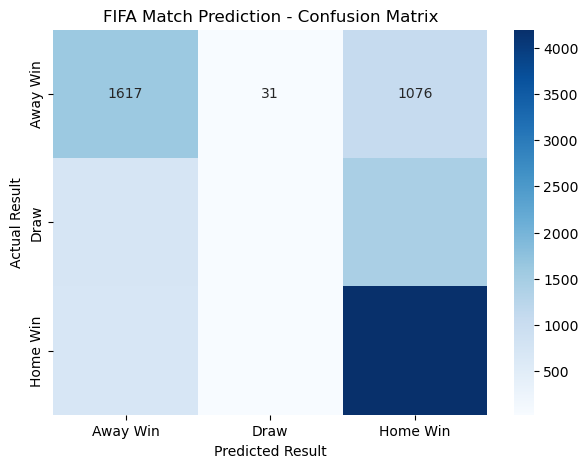

In [237]:
# Confusion Matrix - Final Model

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


# Create confusion matrix

cm = confusion_matrix(
    y_test,
    gb_pred
)


# Plot confusion matrix

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        'Away Win',
        'Draw',
        'Home Win'
    ],
    yticklabels=[
        'Away Win',
        'Draw',
        'Home Win'
    ]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("FIFA Match Prediction - Confusion Matrix")

plt.show()

In [238]:
# Save the image

# plt.savefig(
#     "confusion_matrix.png",
#     dpi=300,
#     bbox_inches='tight'
# )

# Extract Feature Importance

In [239]:
# Feature Importance - Gradient Boosting

import pandas as pd

# Get importance scores
feature_importance = pd.DataFrame({

    'Feature': X_train.columns,
    'Importance': gb_model.feature_importances_

})


# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)


feature_importance

,Feature,Importance
11,elo_difference,0.718592
12,fifa_rank_difference,0.081771
0,neutral,0.031758
8,away_avg_conceded,0.030722
7,home_avg_conceded,0.029435
2,away_win_percentage,0.025419
6,away_avg_goals,0.020901
1,home_win_percentage,0.018049
10,away_goal_difference,0.014295
5,home_avg_goals,0.010590


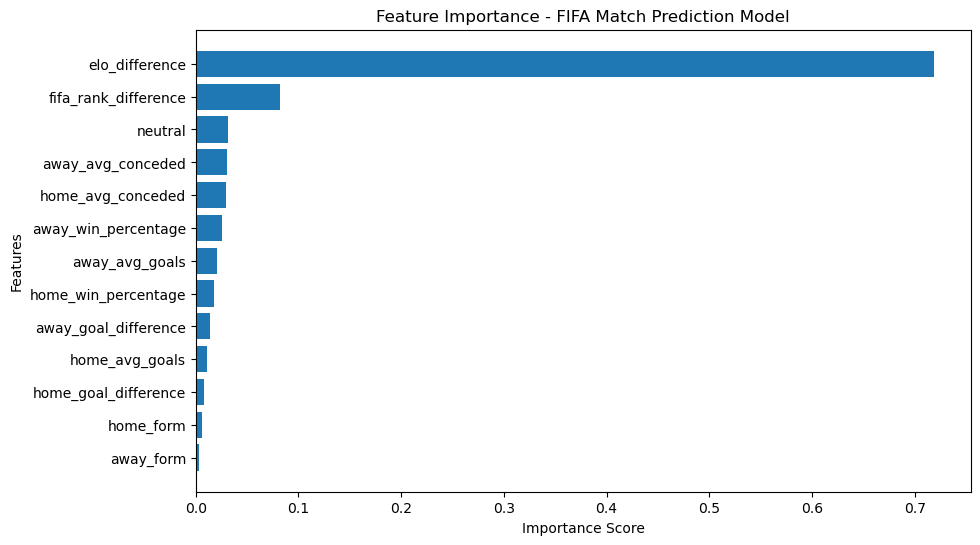

In [240]:
# Visualize it

import matplotlib.pyplot as plt


plt.figure(figsize=(10,6))


plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)


plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Feature Importance - FIFA Match Prediction Model")


plt.gca().invert_yaxis()

plt.show()

In [241]:
# Save the image

# plt.savefig(
#     "feature_importance.png",
#     dpi=300,
#     bbox_inches='tight'
# )

# Save the Model

In [242]:
# Save Final FIFA Prediction Model

import joblib

# Save trained Gradient Boosting model
joblib.dump(
    gb_model,
    "fifa_wc_2026_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [243]:
# Load model back

loaded_model = joblib.load(
    "fifa_wc_2026_model.pkl"
)

print(loaded_model)

GradientBoostingClassifier(random_state=42)


# Build the Prediction Function

In [244]:
# Current Team Statistics

team_stats = {

    "Brazil": {
        "win_percentage": 0.70,
        "form": 0.80,
        "avg_goals": 2.1,
        "avg_conceded": 0.8,
        "goal_difference": 1.3,
        "elo": 2100,
        "fifa_rank": 5
    },


    "Germany": {
        "win_percentage": 0.65,
        "form": 0.70,
        "avg_goals": 1.9,
        "avg_conceded": 1.0,
        "goal_difference": 0.9,
        "elo": 2050,
        "fifa_rank": 8
    }

}

In [254]:
# Create prediction function

import pandas as pd
import numpy as np


def predict_match(home_team, away_team, neutral=True):

    # Get team data
    home = team_stats[home_team]
    away = team_stats[away_team]


    # Create feature dataframe
    match_features = pd.DataFrame({

        "neutral": [1 if neutral else 0],

        "home_win_percentage": [
            home["win_percentage"]
        ],

        "away_win_percentage": [
            away["win_percentage"]
        ],


        "home_form": [
            home["form"]
        ],

        "away_form": [
            away["form"]
        ],


        "home_avg_goals": [
            home["avg_goals"]
        ],

        "away_avg_goals": [
            away["avg_goals"]
        ],


        "home_avg_conceded": [
            home["avg_conceded"]
        ],

        "away_avg_conceded": [
            away["avg_conceded"]
        ],


        "home_goal_difference": [
            home["goal_difference"]
        ],

        "away_goal_difference": [
            away["goal_difference"]
        ],


        "elo_difference": [
            home["elo"] - away["elo"]
        ],


        "fifa_rank_difference": [
            away["fifa_rank"] - home["fifa_rank"]
        ]

    })


    # Prediction probabilities
    probabilities = gb_model.predict_proba(
        match_features
    )[0]


    results = {
        "Away Win": probabilities[0],
        "Draw": probabilities[1],
        "Home Win": probabilities[2]
    }


    print(
        f"\n{home_team} vs {away_team}\n"
    )


    for result, probability in results.items():

        print(
            f"{result}: {probability:.2%}"
        )


    prediction = max(
        results,
        key=results.get
    )


    print(
        "\nPrediction:",
        prediction
    )

In [255]:
# Test it

predict_match(
    "Brazil",
    "Germany",
    neutral=True
)


Brazil vs Germany

Away Win: 42.60%
Draw: 25.86%
Home Win: 31.53%

Prediction: Away Win
